# 03c. Model Training: Random Forest
Trains a **Random Forest** (bagging ensemble of trees) on the output of `featureEngineering.ipynb` (`processed/{train,val,test}/model_data.npz`).

**Task:** every row is one GPS point x one candidate arc; target = `on_route` (binary). The model outputs P(on_route), usable later as an HMM emission score.

**Protocol**
- Group-aware CV (`GroupKFold` by subject) on train + val subjects.
- Final fit on the `train` split.
- `test` = the 10 student-test trips, development comparison only. Evaluator data is never used.

Macro F1 here is over the two classes (on-route / off-route): arc IDs are local to each trip, so per-arc macro F1 is not meaningful.

## Imports and configuration

In [1]:
import json, os, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, log_loss,
                             precision_score, recall_score)
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier

MODEL_NAME = "RandomForest"
PROCESSED = next(p for p in ["../preProcessing", "preProcessing", "processed"] if os.path.isdir(p))
print("reading data from:", os.path.abspath(PROCESSED))
OUT = "results"
N_FOLDS = 5
SEED = 42
os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

reading data from: c:\Users\Noothan\Downloads\PathSnap\preProcessing


## Load data

In [2]:
def load_split(split):
    # allow_pickle=True: featureEngineering.ipynb saved `groups` as an object array (your own file)
    z = np.load(os.path.join(PROCESSED, split, "model_data.npz"), allow_pickle=True)
    meta = pd.DataFrame({
        "subject_id": z["groups"].astype(str), "point_idx": z["point_idx"],
        "seg_id": z["seg_id"], "arc_id": z["arc_id"],
        "y": z["y"].astype(int), "y_true_arc": z["y_true_arc"].astype(int)})
    return z["X"], meta, [str(f) for f in z["feature_names"]]

Xtr, mtr, FEATURES = load_split("train")
Xva, mva, _ = load_split("val")
Xte, mte, _ = load_split("test")
print("train", Xtr.shape, "| val", Xva.shape, "| test", Xte.shape)
print("features:", FEATURES)

# CV pool = train + val subjects
Xcv = np.vstack([Xtr, Xva])
mcv = pd.concat([mtr, mva], ignore_index=True)
ycv, groups = mcv["y"].to_numpy(), mcv["subject_id"].to_numpy()

# leakage check: no subject shared between development data and student-test
assert not (set(mtr.subject_id) | set(mva.subject_id)) & set(mte.subject_id)
print("subjects  CV pool:", len(set(groups)), "| test:", mte.subject_id.nunique())
print("positive rate  train %.3f | val %.3f | test %.3f" % (mtr.y.mean(), mva.y.mean(), mte.y.mean()))

train (1347223, 19) | val (313307, 19) | test (171447, 19)
features: ['dist', 'dist_rank', 'dist_minus_min', 'n_within_50m', 'frac_along', 'arc_len', 'head_diff_cos', 'head_valid', 'arc_sin', 'arc_cos', 'end_outdeg', 'start_indeg', 'dist_to_start', 'dist_to_end', 'speed', 'dt', 'accel', 'turn_rate', 'seg_pos']
subjects  CV pool: 78 | test: 10
positive rate  train 0.379 | val 0.332 | test 0.401


## Road networks (for route continuity)
Loaded from `interim.pkl`, which your own `dataProcessing.ipynb` wrote. If it is missing, route continuity is reported as N/A.

In [3]:
pkl = os.path.join(PROCESSED, "interim", "interim.pkl")
networks = None
if os.path.exists(pkl):
    with open(pkl, "rb") as f:
        networks = pickle.load(f)["networks"]
else:
    print("interim.pkl not found -> route_continuity = N/A")

interim.pkl not found -> route_continuity = N/A


## Metric functions
- **Candidate-level:** accuracy, precision, recall, macro F1, log loss (threshold 0.5).
- **Point-level:** for each GPS point take the highest-scoring candidate.
  - `top1_on_route`: chosen arc is on the true route (lenient).
  - `top1_true_arc`: chosen arc equals `is_true_arc` (strict).
  - `candidate_miss_rate`: points with no on-route arc among their candidates.
  - `route_continuity`: among consecutive points of the same subject and segment, share of predicted arc pairs that are the same arc or end-to-start connected. It is conservative, because at 1 Hz a fast vehicle can skip a short arc.

In [4]:
def candidate_metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return dict(
        accuracy=accuracy_score(y, pred),
        precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred, zero_division=0),
        macro_f1=f1_score(y, pred, average="macro", zero_division=0),
        log_loss=log_loss(y, np.clip(p, 1e-7, 1 - 1e-7), labels=[0, 1]))


def point_metrics(meta, p):
    d = meta.assign(score=p).sort_values(["subject_id", "point_idx"]).reset_index(drop=True)
    g = d.groupby(["subject_id", "point_idx"], sort=False)
    top = d.loc[g["score"].idxmax()].reset_index(drop=True)
    has_true = g["y"].max().to_numpy()
    out = dict(n_points=len(top),
               top1_on_route=float(top["y"].mean()),
               top1_true_arc=float(top["y_true_arc"].mean()),
               candidate_miss_rate=float(1 - has_true.mean()),
               top1_on_route_given_hit=float(top.loc[has_true == 1, "y"].mean()))
    cont = np.nan
    if networks is not None:
        ok = tot = 0
        for sid, s in top.groupby("subject_id"):
            net = networks[sid]
            a, seg = s["arc_id"].to_numpy(), s["seg_id"].to_numpy()
            same = seg[1:] == seg[:-1]
            prev, cur = a[:-1][same], a[1:][same]
            conn = (net["canon_id"][prev] == net["canon_id"][cur]) | (net["arcs"][prev, 1] == net["arcs"][cur, 0])
            ok += int(conn.sum()); tot += int(len(conn))
        cont = ok / tot if tot else np.nan
    out["route_continuity"] = cont
    return out

## Model
Bagged decision trees; probabilities are the average of the trees' leaf fractions, so they are smoother than a single tree's. Each tree sees a random 30% subsample of the rows (`max_samples=0.3`) to keep training time manageable on ~1.5M rows. Hyperparameters are reasonable starting values and are **not tuned**.

In [5]:
def make_model():
    return RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=20,
                                  max_features='sqrt', max_samples=0.3, n_jobs=-1, random_state=SEED)

CONFIG_KEYS = ('n_estimators', 'max_depth', 'min_samples_leaf', 'max_features', 'max_samples', 'random_state')

def proba_timed(model, X):
    t = time.perf_counter()
    p = model.predict_proba(X)[:, 1]
    return p, time.perf_counter() - t

## Group-aware cross-validation (train + val subjects)

In [6]:
rows = []
for k, (tr, va) in enumerate(GroupKFold(n_splits=N_FOLDS).split(Xcv, ycv, groups)):
    m = make_model()
    m.fit(Xcv[tr], ycv[tr])
    p, _ = proba_timed(m, Xcv[va])
    r = candidate_metrics(ycv[va], p)
    r.update(point_metrics(mcv.iloc[va], p))
    r["fold"] = k
    rows.append(r)
    print(f"fold {k}: macroF1={r['macro_f1']:.4f}  top1={r['top1_on_route']:.4f}")
cv = pd.DataFrame(rows)
cv.to_csv(os.path.join(OUT, f"{MODEL_NAME}_cv_folds.csv"), index=False)
cv[["macro_f1", "top1_on_route", "log_loss"]].agg(["mean", "std"]).round(4)

fold 0: macroF1=0.7555  top1=0.7506
fold 1: macroF1=0.8312  top1=0.8565
fold 2: macroF1=0.8372  top1=0.9098
fold 3: macroF1=0.8323  top1=0.8888
fold 4: macroF1=0.7714  top1=0.8260


,macro_f1,top1_on_route,log_loss
mean,0.8055,0.8463,0.4068
std,0.0389,0.0623,0.0438


## Final fit on `train`, evaluate on student-test

In [7]:
model = make_model()
t = time.perf_counter()
model.fit(Xtr, mtr["y"].to_numpy())
train_time = time.perf_counter() - t
p_te, inf_time = proba_timed(model, Xte)
te = candidate_metrics(mte["y"].to_numpy(), p_te)
te.update(point_metrics(mte, p_te))

cm = confusion_matrix(mte["y"].to_numpy(), (p_te >= 0.5).astype(int))
np.savetxt(os.path.join(OUT, f"{MODEL_NAME}_confusion_test.csv"), cm, fmt="%d", delimiter=",")
np.save(os.path.join(OUT, f"{MODEL_NAME}_test_scores.npy"), p_te.astype(np.float32))
with open(os.path.join(OUT, f"{MODEL_NAME}.pkl"), "wb") as f:
    pickle.dump(model, f)

summary = dict(
    Model=MODEL_NAME,
    Key_configuration=json.dumps({k: v for k, v in model.get_params().items() if k in CONFIG_KEYS}),
    CV_macro_f1=cv.macro_f1.mean(), CV_macro_f1_std=cv.macro_f1.std(),
    CV_top1=cv.top1_on_route.mean(), CV_log_loss=cv.log_loss.mean(),
    Test_macro_f1=te["macro_f1"], Test_accuracy=te["accuracy"],
    Test_precision=te["precision"], Test_recall=te["recall"],
    Test_top1_on_route=te["top1_on_route"], Test_top1_true_arc=te["top1_true_arc"],
    Test_candidate_miss_rate=te["candidate_miss_rate"],
    Test_route_continuity=te["route_continuity"], Test_log_loss=te["log_loss"],
    Train_time_s=train_time, Inference_time_s=inf_time,
    Inference_us_per_row=1e6 * inf_time / len(Xte), seed=SEED)
pd.DataFrame([summary]).to_csv(os.path.join(OUT, f"{MODEL_NAME}_summary.csv"), index=False)
pd.Series(summary).drop("Key_configuration").to_frame("value").round(4)

,value
Model,RandomForest
CV_macro_f1,0.805515
CV_macro_f1_std,0.038912
CV_top1,0.84632
CV_log_loss,0.406833
Test_macro_f1,0.78599
Test_accuracy,0.802079
Test_precision,0.812602
Test_recall,0.658225
Test_top1_on_route,0.883443


## Train vs validation vs test
Training metrics are optimistic (the model has seen those rows) and are used only to judge overfitting. Model comparison uses CV and student-test.

In [8]:
# Train vs validation vs student-test (training metrics are for overfitting diagnosis only)
p_tr, _ = proba_timed(model, Xtr)
tr_m = candidate_metrics(mtr["y"].to_numpy(), p_tr); tr_m.update(point_metrics(mtr, p_tr))
p_va, _ = proba_timed(model, Xva)
va_m = candidate_metrics(mva["y"].to_numpy(), p_va); va_m.update(point_metrics(mva, p_va))

cmp_df = pd.DataFrame({"train": tr_m, "val": va_m, "student_test": te}).loc[
    ["accuracy", "precision", "recall", "macro_f1", "log_loss", "top1_on_route", "top1_true_arc"]]
cmp_df["train_minus_val"] = cmp_df["train"] - cmp_df["val"]
cmp_df.to_csv(os.path.join(OUT, f"{MODEL_NAME}_train_val_test.csv"))
cmp_df.round(4)

,train,val,student_test,train_minus_val
accuracy,0.8790,0.8426,0.8021,0.0365
precision,0.8706,0.7792,0.8126,0.0914
recall,0.7997,0.7347,0.6582,0.0650
macro_f1,0.8693,0.8200,0.7860,0.0493
log_loss,0.3055,0.3739,0.4814,-0.0685
top1_on_route,0.9197,0.8571,0.8834,0.0626
top1_true_arc,0.7901,0.7457,0.7925,0.0444


## Plots (from the measured results only)

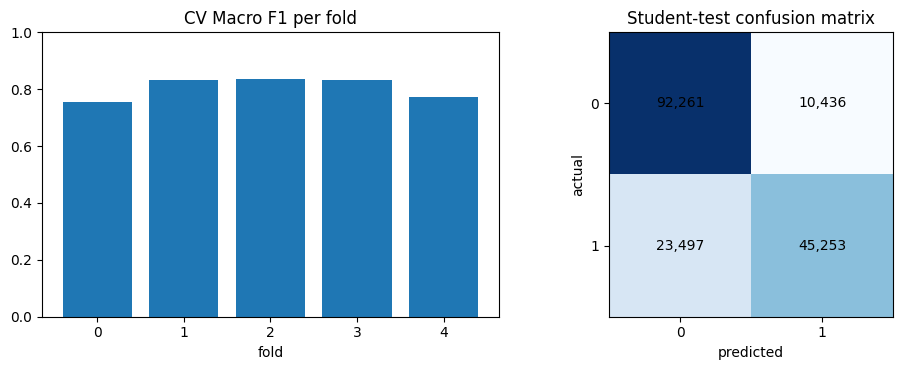

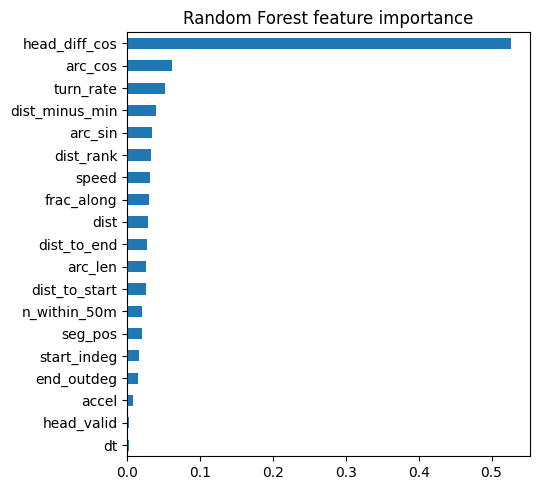

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(cv["fold"].astype(str), cv["macro_f1"]); axes[0].set_title("CV Macro F1 per fold")
axes[0].set_xlabel("fold"); axes[0].set_ylim(0, 1)
axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center")
axes[1].set_title("Student-test confusion matrix"); axes[1].set_xlabel("predicted"); axes[1].set_ylabel("actual")
axes[1].set_xticks([0, 1]); axes[1].set_yticks([0, 1])
plt.tight_layout(); plt.savefig(os.path.join(OUT, f"{MODEL_NAME}_plots.png"), dpi=150); plt.show()
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(5.5, 5)); imp.plot.barh(); plt.title("Random Forest feature importance")
plt.tight_layout(); plt.savefig(os.path.join(OUT, f"{MODEL_NAME}_feature_importance.png"), dpi=150); plt.show()

## Notes for the report
- A random forest has no epoch-wise history, so there is no loss curve for it.
- Compare train, validation and test in the table above: a large train-minus-val gap indicates overfitting.
- Training metrics are for diagnosis only, not for model selection.
- Report only the numbers produced by running this notebook.

In [11]:

import os
import joblib
import numpy as np

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    log_loss
)

# Check current working directory
print("Current directory:", os.getcwd())

# Correct paths when notebook is inside models/
model_path = Path("results/RandomForest.pkl")
data_path = Path("../preProcessing/val/model_data.npz")

# Load model
model = joblib.load(model_path)

# Load validation data
data = np.load(data_path, allow_pickle=False)

X_val = data["X"]
y_val = data["y"]

print("Validation features shape:", X_val.shape)
print("Validation labels shape:", y_val.shape)

# Generate predictions
y_pred = model.predict(X_val)

# Evaluate
print("\nValidation Accuracy:", accuracy_score(y_val, y_pred))
print("Validation Macro F1:", f1_score(y_val, y_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

if hasattr(model, "predict_proba"):
    y_prob = model.predict_proba(X_val)
    print("Validation Log Loss:", log_loss(y_val, y_prob))


Current directory: c:\Users\Noothan\Downloads\PathSnap\models
Validation features shape: (313307, 19)
Validation labels shape: (313307,)

Validation Accuracy: 0.8425761313982771
Validation Macro F1: 0.8200060467245733

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.90      0.88    209150
           1       0.78      0.73      0.76    104157

    accuracy                           0.84    313307
   macro avg       0.83      0.82      0.82    313307
weighted avg       0.84      0.84      0.84    313307

Validation Log Loss: 0.37391531887711976


In [12]:
import numpy as np

data = np.load("../preProcessing/val/model_data.npz", allow_pickle=False)

print(data.files)

['X', 'y', 'y_true_arc', 'groups', 'point_idx', 'seg_id', 'arc_id', 'feature_names']


In [14]:
import numpy as np

train_data = np.load(
    "../preProcessing/train/model_data.npz",
    allow_pickle=True
)

print("Available arrays:", train_data.files)

Available arrays: ['X', 'y', 'y_true_arc', 'groups', 'point_idx', 'seg_id', 'arc_id', 'feature_names']


In [15]:
X_train = train_data["X"]
y_train = train_data["y"]

print("Training features shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Number of training trips:",
      len(np.unique(train_data["groups"])))

print("Number of training GPS points:",
      len(set(zip(train_data["groups"], train_data["point_idx"]))))

Training features shape: (1347223, 19)
Training labels shape: (1347223,)
Number of training trips: 62
Number of training GPS points: 150182
